# Decision Tree | Edge-IIoTset | target: `Attack_type` (15-class, macro-averaged)
Tayyab (SP24-BCS-004).

## 1. Imports and setup
**Q1.** Import the libraries and set a global `RANDOM_STATE`.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             log_loss, matthews_corrcoef, confusion_matrix, classification_report)

RANDOM_STATE = 42

**Q2.** Define the Decision Tree hyperparameters and the duplicate-removal switch.

In [2]:
# Dataset-specific hyperparameters (see HYPERPARAMETER_SOURCES.md)
# Source: Kuo & Wu (2026), "A Lightweight Two-Stage Intrusion Detection Framework Optimized for Edge-Based IoT
# Environments", Computers, Materials & Continua 87(3):53, doi:10.32604/cmc.2026.076767
# ("Decision Tree was implemented using Scikit-learn with default hyperparameters": gini, max_depth None,
#  min_samples_split 2, splitter "best"). Their tree was trained on CICIoT2023; Edge-IIoTset was used to test the framework.
# The Edge-IIoTset paper (Ferrag et al. 2022, IEEE Access, doi:10.1109/ACCESS.2022.3165809) did not publish its DT values.
HP = dict(criterion="gini", splitter="best", max_depth=None, min_samples_split=2, min_samples_leaf=1, random_state=RANDOM_STATE)

# Previous values (Li et al. 2024 / Sharma et al. 2025): max_depth=5, min_samples_split=5 -> underfitted Attack_type

# Still undecided in the team (AUDIT_LOG O2), kept False like TON_IoT
DEDUPLICATE = False

## 2. Load the dataset
**Q3.** Load `ML-EdgeIIoT-dataset.csv`. How many rows and columns are there?

In [3]:
# low_memory=False: some columns mix text and numbers, so pandas reads the whole file before choosing types
df = pd.read_csv("../../../ML-EdgeIIoT-dataset.csv", low_memory=False)

In [4]:
df.shape

(157800, 63)

## 3. Explore the data
**Q4.** Show `head()`, `info()`, `describe()` and the class distribution of `Attack_type`. Is it balanced? Which class is the rarest?

In [5]:
df.head()

,frame.time,ip.src_host,ip.dst_host,arp.dst.proto_ipv4,arp.opcode,arp.hw.size,arp.src.proto_ipv4,icmp.checksum,icmp.seq_le,icmp.transmit_timestamp,...,mqtt.proto_len,mqtt.protoname,mqtt.topic,mqtt.topic_len,mqtt.ver,mbtcp.len,mbtcp.trans_id,mbtcp.unit_id,Attack_label,Attack_type
0,6.0,192.168.0.152,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM
1,6.0,192.168.0.101,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM
2,6.0,192.168.0.152,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM
3,6.0,192.168.0.101,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM
4,6.0,192.168.0.152,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 157800 entries, 0 to 157799
Data columns (total 63 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   frame.time                 157800 non-null  str    
 1   ip.src_host                157800 non-null  str    
 2   ip.dst_host                157800 non-null  str    
 3   arp.dst.proto_ipv4         157800 non-null  str    
 4   arp.opcode                 157800 non-null  float64
 5   arp.hw.size                157800 non-null  float64
 6   arp.src.proto_ipv4         157800 non-null  str    
 7   icmp.checksum              157800 non-null  float64
 8   icmp.seq_le                157800 non-null  float64
 9   icmp.transmit_timestamp    157800 non-null  float64
 10  icmp.unused                157800 non-null  float64
 11  http.file_data             157800 non-null  str    
 12  http.content_length        157800 non-null  float64
 13  http.request.uri.query     157800 non-nu

In [7]:
df.describe()

,arp.opcode,arp.hw.size,icmp.checksum,icmp.seq_le,icmp.transmit_timestamp,icmp.unused,http.content_length,http.response,http.tls_port,tcp.ack,...,mqtt.len,mqtt.msg_decoded_as,mqtt.msgtype,mqtt.proto_len,mqtt.topic_len,mqtt.ver,mbtcp.len,mbtcp.trans_id,mbtcp.unit_id,Attack_label
count,157800.000000,157800.000000,157800.000000,157800.000000,1.578000e+05,157800.0,157800.000000,157800.000000,157800.0,1.578000e+05,...,157800.000000,157800.0,157800.000000,157800.000000,157800.000000,157800.000000,157800.0,157800.0,157800.0,157800.000000
mean,0.014195,0.059848,3047.291838,3239.979778,4.046816e+04,0.0,14.715520,0.045748,0.0,7.160039e+07,...,0.419341,0.0,0.161331,0.031686,0.189506,0.031686,0.0,0.0,0.0,0.846001
std,0.149783,0.596245,11144.328203,11406.072994,1.764075e+06,0.0,229.659671,0.208938,0.0,3.101231e+08,...,3.606594,0.0,1.293453,0.354598,2.124206,0.354598,0.0,0.0,0.0,0.360949
min,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.0,0.000000,0.000000,0.0,0.000000e+00,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.0,0.000000,0.000000,0.0,0.000000e+00,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,1.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.0,0.000000,0.000000,0.0,1.000000e+00,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,1.000000
75%,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.0,0.000000,0.000000,0.0,4.790000e+02,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,1.000000
max,2.000000,6.000000,65532.000000,65524.000000,7.728902e+07,0.0,83655.000000,1.000000,0.0,2.147333e+09,...,39.000000,0.0,14.000000,4.000000,24.000000,4.000000,0.0,0.0,0.0,1.000000


<Axes: title={'center': 'Class distribution: Attack_type'}, xlabel='Attack_type'>

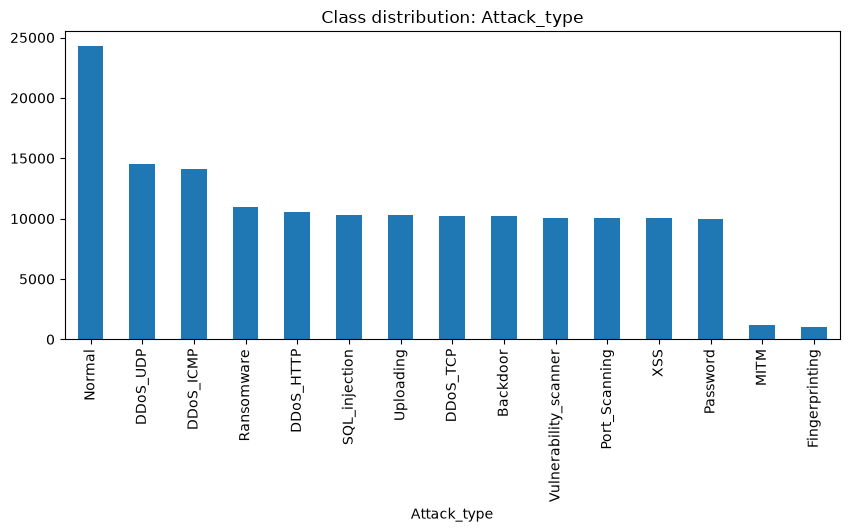

In [8]:
df["Attack_type"].value_counts().plot(kind="bar", figsize=(10, 4), title="Class distribution: Attack_type")

In [9]:
df["Attack_type"].value_counts(normalize=True).round(4)

Attack_type
Normal                   0.1540
DDoS_UDP                 0.0919
DDoS_ICMP                0.0893
Ransomware               0.0692
DDoS_HTTP                0.0669
SQL_injection            0.0653
Uploading                0.0651
DDoS_TCP                 0.0649
Backdoor                 0.0646
Vulnerability_scanner    0.0639
Port_Scanning            0.0638
XSS                      0.0637
Password                 0.0633
MITM                     0.0077
Fingerprinting           0.0063
Name: proportion, dtype: float64

**Q5.** How are missing values marked in this dataset, and how many are there?

In [10]:
df.isnull().sum().sum()

np.int64(0)

In [11]:
# The same "empty" field written two ways in a text column
df["http.request.method"].value_counts()

http.request.method
0.0        96542
0          54062
GET         6676
POST         267
TRACE        252
OPTIONS        1
Name: count, dtype: int64

## 4. Clean the data
**Q6.** Which columns have the same value in every row? Drop them.

In [12]:
# A column with only one value cannot help the tree split anything
constant_cols = [col for col in df.columns if df[col].nunique() == 1]
constant_cols

['icmp.unused',
 'http.tls_port',
 'dns.qry.type',
 'dns.retransmit_request_in',
 'mqtt.msg_decoded_as',
 'mbtcp.len',
 'mbtcp.trans_id',
 'mbtcp.unit_id']

In [13]:
df = df.drop(columns=constant_cols)
df.shape

(157800, 55)

**Q7.** Drop the identifier columns and the raw-content columns. Why do they cause overfitting?

In [14]:
# Identifiers: a tree that memorised them would not work on a different network or day
id_cols = ["frame.time", "icmp.transmit_timestamp",
           "ip.src_host", "ip.dst_host", "arp.src.proto_ipv4", "arp.dst.proto_ipv4",
           "tcp.srcport", "tcp.dstport", "udp.port"]

# Raw content: free text that is almost unique per row, so it only adds noise
raw_cols = ["http.file_data", "http.request.full_uri", "http.request.uri.query",
            "tcp.options", "tcp.payload", "mqtt.msg"]

df = df.drop(columns=id_cols + raw_cols)
df.shape

(157800, 40)

**Q8.** How many duplicate rows are there now?

In [15]:
no_of_duplicates = df.duplicated().sum()
no_of_duplicates

np.int64(5604)

In [16]:
if DEDUPLICATE:
    df = df.drop_duplicates().reset_index(drop=True)
df.shape

(157800, 40)

## 5. Targets and split
**Q9.** Build the features `X` and the target `y` (`Attack_type`), then split 80/20 with stratification. Do the class shares match between train and test?

In [17]:
# Both targets leave the features, otherwise the model would just read the answer
X = df.drop(columns=["Attack_label", "Attack_type"])

# The tree needs numbers, so the 15 class names become 0..14 (alphabetical)
le = LabelEncoder()
y = pd.Series(le.fit_transform(df["Attack_type"]), index=df.index)
class_names = list(le.classes_)

# Stratify on Attack_type in both notebooks, so the label and type models use the exact same rows
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=df["Attack_type"])
X_train.shape, X_test.shape

((126240, 38), (31560, 38))

In [18]:
# Class shares should be (almost) the same in train and test
pd.DataFrame({"train": y_train.value_counts(normalize=True), "test": y_test.value_counts(normalize=True)}).round(4)

,train,test
7,0.1540,0.1540
4,0.0919,0.0919
2,0.0893,0.0893
10,0.0692,0.0692
1,0.0669,0.0669
11,0.0653,0.0653
12,0.0651,0.0651
3,0.0649,0.0650
0,0.0646,0.0646
13,0.0639,0.0638


## 6. Encode the features
**Q10.** Encode the features. Why are the encoders fitted after the split? Why is no scaling needed for trees?

In [19]:
# The only text columns left; each has just a few different values, so one-hot is fine
onehot_cols = ["http.request.method", "http.referer", "http.request.version", "dns.qry.name.len",
               "mqtt.conack.flags", "mqtt.protoname", "mqtt.topic"]

X_train = X_train.copy()
X_test = X_test.copy()

for col in onehot_cols:
    # "0" and "0.0" both mean "field not used", so they become one category
    X_train[col] = X_train[col].astype(str).replace("0", "0.0")
    X_test[col] = X_test[col].astype(str).replace("0", "0.0")

# Columns come from the training set; the test set is lined up to them (unseen categories dropped, missing ones = 0)
X_train = pd.get_dummies(X_train, columns=onehot_cols, dtype=int)
X_test = pd.get_dummies(X_test, columns=onehot_cols, dtype=int).reindex(columns=X_train.columns, fill_value=0)

# No scaling: a tree only compares a feature with a threshold, so the scale does not matter
X_train.shape, X_test.shape

((126240, 59), (31560, 59))

## 7. Validation with stratified 5-fold
**Q11.** Run stratified 5-fold validation with the fixed hyperparameters. Is the validation score stable across the folds?

In [20]:
# 5 rounds on the 80%: each round trains on 4 parts (64% of all data) and validates on 1 part (16%)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

fold_scores = []
for fold, (train_idx, val_idx) in enumerate(skf.split(X_train, y_train), start=1):
    m = DecisionTreeClassifier(**HP)
    m.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
    pred = m.predict(X_train.iloc[val_idx])
    fold_scores.append({"fold": fold,
                        "val_accuracy": accuracy_score(y_train.iloc[val_idx], pred),
                        "val_f1_macro": f1_score(y_train.iloc[val_idx], pred, average="macro")})

fold_df = pd.DataFrame(fold_scores).set_index("fold")
fold_df.round(4)

,val_accuracy,val_f1_macro
fold,,
1,0.8556,0.8169
2,0.8566,0.8181
3,0.8562,0.8172
4,0.8598,0.8212
5,0.8537,0.8124


In [21]:
# Mean and spread over the 5 folds (small std = stable model)
fold_df.agg(["mean", "std"]).round(4)

,val_accuracy,val_f1_macro
mean,0.8564,0.8172
std,0.0022,0.0031


## 8. Final model
**Q12.** Train the final model on the full training set. How long does it take? How deep is the tree, and how many leaves does it have?

In [22]:
model = DecisionTreeClassifier(**HP)

start = time.perf_counter()
model.fit(X_train, y_train)
train_time = time.perf_counter() - start

train_time, model.get_depth(), model.get_n_leaves()

(0.9694024999917019, 94, np.int64(13933))

## 9. Evaluation on the test set (used more than once: `max_depth` was revised after the first test results)
**Q13.** Predict on the test set and measure the inference latency (ms per sample).

In [23]:
# Latency = predict() time on the whole test set / number of test rows, in ms per sample
start = time.perf_counter()
y_pred = model.predict(X_test)
latency_ms = (time.perf_counter() - start) / len(X_test) * 1000

# Probabilities are needed for ROC-AUC and Log-Loss
y_proba = model.predict_proba(X_test)
latency_ms

0.0004502978445965022

**Q14.** Compute Accuracy, Precision, Recall, F1, ROC-AUC, Log-Loss, FPR, MCC and TP/TN/FP/FN (macro-averaged). Which classes are the hardest?

In [24]:
labels = np.arange(len(class_names))

# Macro = compute per class, then take the plain average, so small classes count as much as big ones
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
recall = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)
roc_auc = roc_auc_score(y_test, y_proba, multi_class="ovr", average="macro", labels=labels)
logloss = log_loss(y_test, y_proba, labels=labels)
mcc = matthews_corrcoef(y_test, y_pred)

# One-vs-rest counts per class from the confusion matrix (rows = actual, columns = predicted)
cm = confusion_matrix(y_test, y_pred, labels=labels)
TP = np.diag(cm)
FP = cm.sum(axis=0) - TP
FN = cm.sum(axis=1) - TP
TN = cm.sum() - (TP + FP + FN)
fpr = np.mean(FP / (FP + TN))

pd.Series({"Accuracy": accuracy, "Precision": precision, "Recall": recall, "F1": f1,
           "ROC-AUC": roc_auc, "Log-Loss": logloss, "FPR": fpr, "MCC": mcc}).round(4)

Accuracy     0.8573
Precision    0.8161
Recall       0.8425
F1           0.8201
ROC-AUC      0.9282
Log-Loss     4.5661
FPR          0.0103
MCC          0.8447
dtype: float64

In [25]:
# Per-class view: which attack types does the shallow tree miss?
print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))

                       precision    recall  f1-score   support

             Backdoor       0.94      0.91      0.93      2039
            DDoS_HTTP       0.72      0.72      0.72      2112
            DDoS_ICMP       1.00      1.00      1.00      2818
             DDoS_TCP       1.00      1.00      1.00      2050
             DDoS_UDP       1.00      1.00      1.00      2900
       Fingerprinting       0.68      0.60      0.64       200
                 MITM       0.40      1.00      0.57       243
               Normal       0.88      0.87      0.87      4860
             Password       0.75      0.76      0.76      1998
        Port_Scanning       0.82      0.87      0.85      2014
           Ransomware       0.89      0.80      0.84      2185
        SQL_injection       0.73      0.77      0.75      2062
            Uploading       0.66      0.64      0.65      2054
Vulnerability_scanner       0.96      0.95      0.96      2015
                  XSS       0.80      0.74      0.77  

In [26]:
# Macro-averaged one-vs-rest counts (these go in Results.xlsx)
TP.mean(), TN.mean(), FP.mean(), FN.mean()

(np.float64(1803.7333333333333),
 np.float64(29155.733333333334),
 np.float64(300.26666666666665),
 np.float64(300.26666666666665))

**Q15.** Compare the train and test accuracy. Is the tree overfitting or underfitting?

In [27]:
# Train much higher than test = overfitting; both low and close = underfitting
train_acc = accuracy_score(y_train, model.predict(X_train))
test_acc = accuracy_score(y_test, y_pred)
round(train_acc, 4), round(test_acc, 4)

(0.9796, 0.8573)

## 10. Visualizations
**Q16.** Plot the confusion matrix.

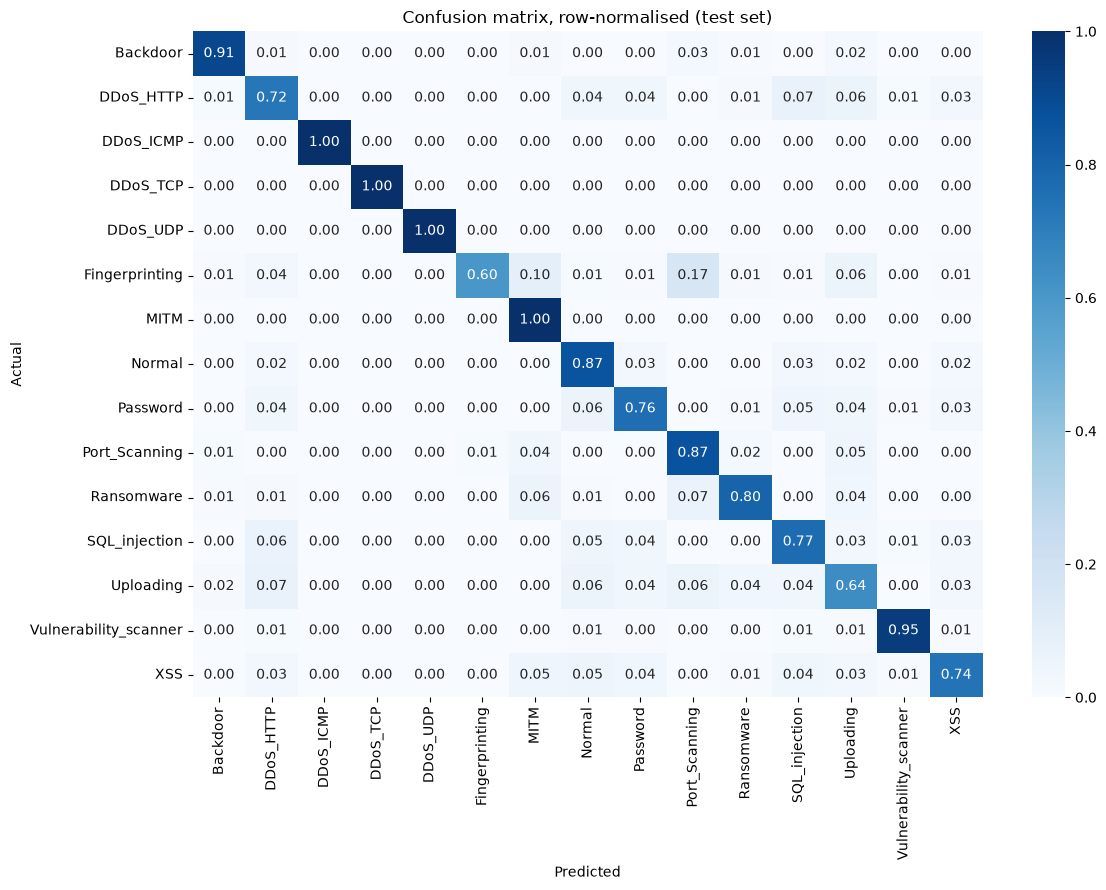

In [28]:
# normalize="true": each row sums to 1, so the diagonal is the recall of each class
cm_norm = confusion_matrix(y_test, y_pred, labels=labels, normalize="true")

plt.figure(figsize=(12, 9))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion matrix, row-normalised (test set)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

**Q17.** Which features matter most to the tree?

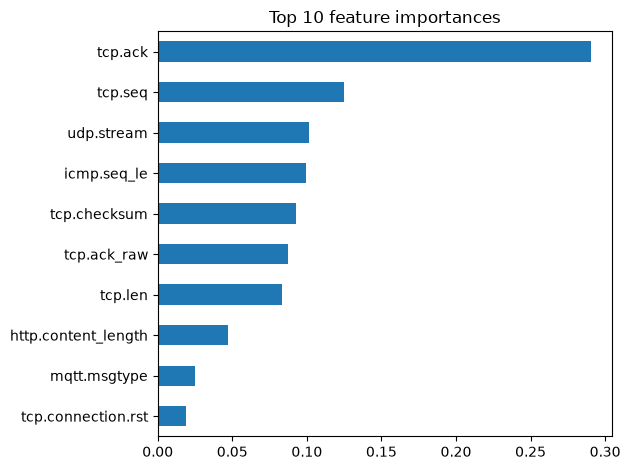

In [29]:
# How much each feature reduced the gini impurity in total (they sum to 1)
importances = pd.Series(model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
importances.head(10).sort_values().plot(kind="barh", title="Top 10 feature importances")
plt.tight_layout()
plt.show()

In [30]:
importances.head(10).round(4)

tcp.ack                0.2902
tcp.seq                0.1252
udp.stream             0.1018
icmp.seq_le            0.0992
tcp.checksum           0.0926
tcp.ack_raw            0.0870
tcp.len                0.0834
http.content_length    0.0470
mqtt.msgtype           0.0251
tcp.connection.rst     0.0190
dtype: float64

**Q18.** Plot the top levels of the tree. Do the first splits make sense for network attacks?

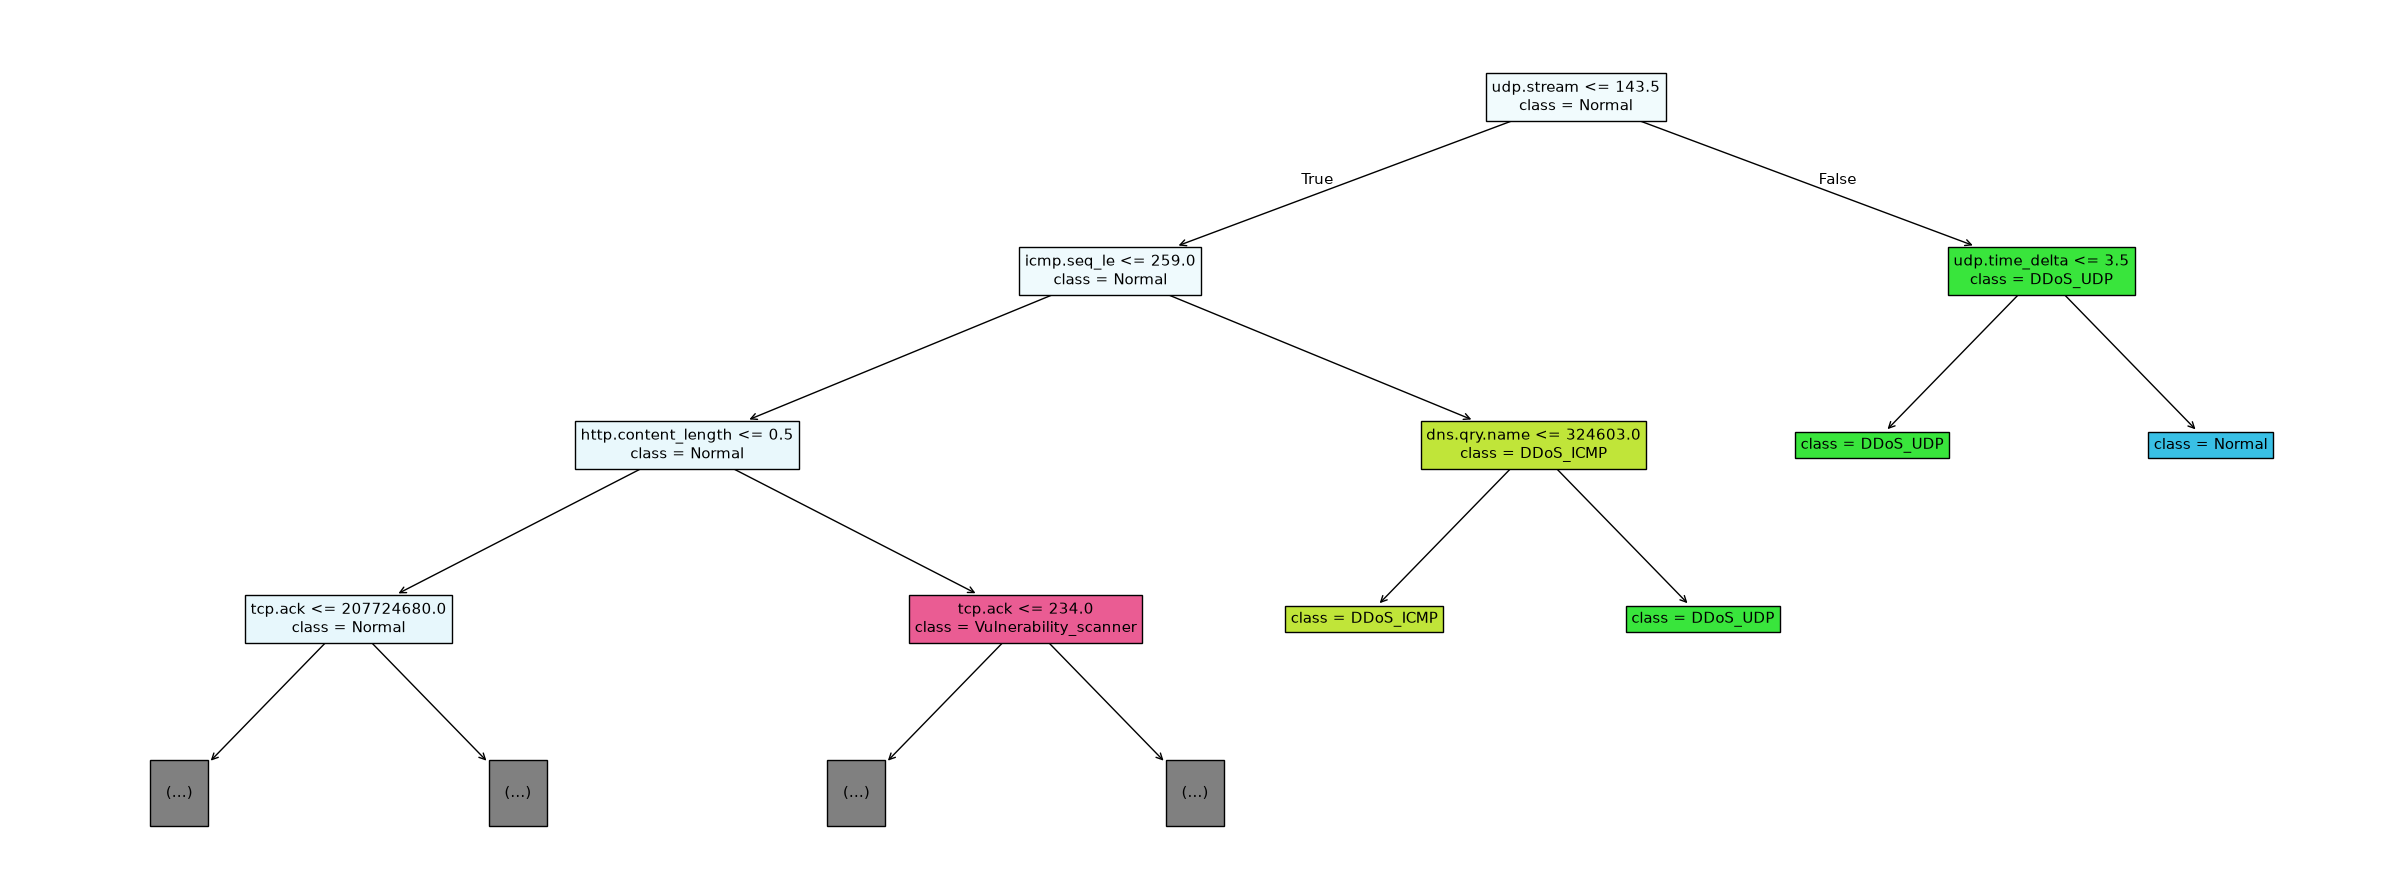

In [31]:
# Only the first 3 levels of the tree
fig, ax = plt.subplots(figsize=(24, 9))
nodes = plot_tree(model, feature_names=list(X_train.columns), class_names=class_names, filled=True,
                  max_depth=3, impurity=False, fontsize=11, ax=ax)

# Keep only the split question and the predicted class in each box;
# the "samples" and "value = [...]" lines make the boxes too wide and they overlap
for node in nodes:
    text = node.get_text()
    if "value" in text:
        keep = [line for line in text.splitlines() if "<=" in line or line.startswith("class")]
        node.set_text("\n".join(keep))

plt.tight_layout()
plt.show()

## 11. Results table
**Q19.** Collect all the numbers in one results table.

In [32]:
results = pd.DataFrame([{
    "Accuracy": accuracy, "Precision": precision, "Recall": recall, "F1-Score": f1,
    "ROC-AUC": roc_auc, "Log-Loss": logloss, "FPR": fpr, "MCC": mcc,
    "Inference Latency (ms/sample)": latency_ms, "Training time (s)": train_time,
    "TP": TP.mean(), "TN": TN.mean(), "FP": FP.mean(), "FN": FN.mean(),
    "Test rows": len(y_test),
}], index=["Decision Tree - Edge-IIoT Attack_type (macro)"])
results.T

,Decision Tree - Edge-IIoT Attack_type (macro)
Accuracy,0.857288
Precision,0.816073
Recall,0.842508
F1-Score,0.820100
ROC-AUC,0.928167
Log-Loss,4.566089
FPR,0.010254
MCC,0.844705
Inference Latency (ms/sample),0.000450
Training time (s),0.969402


## 12. Discussion (for the report)
**Q20.** How does this model compare with the KNN, Random Forest and XGBoost results?

**Q21.** Which attack types are confused with each other, and why?

**Q22.** What are the limitations of this model?

**Your notes:**

